In [1]:
#importing necessary packages 
import pandas as pd 
import os 
import duckdb
import pandera.pandas as pa
from pandera.pandas import Column, DataFrameSchema, Check
import yaml
import datetime
import re 
import matplotlib.pyplot as plt
import numpy as np

Part 1: Loading and Parsing (Data Formats)

Task 1.1 -- Parse the question banks

Load all four YAML files from question_banks/. For each domain, extract the list of knowledge/application questions (i.e., not self-report) into a single pandas DataFrame with at least these columns: domain, question_id, sub_skill, difficulty, dimension, correct_answer.


In [2]:
#opening the yaml files using os  and the filepath 
folder = 'C:/Users/ilian/Downloads/SI_345/DoU 5/si345_dou_5_data/question_banks/'

#creating the list to later turn into a dataframe 
all_questions = []

#opening the yaml files 
for filename in os.listdir(folder):
    file_full_path = os.path.join(folder, filename)

    with open(file_full_path, 'r') as file:
        data = yaml.safe_load(file)

            #using the filename (minus .yaml) as the domain column value
        domain_name = filename.replace('.yaml', '')

#extracting the questions for each 
        for q in data.get('questions', []):
            if q.get('type') != 'self-report':
                all_questions.append({
                        'domain': domain_name,
                        'question_id': q.get('id'),
                        'sub_skill': q.get('sub_skill'),
                        'difficulty': q.get('difficulty'),
                        'dimension': q.get('dimension'),
                        'correct_answer': q.get('correct')
                    })

#turning it into a single pandas df 

yaml_df = pd.DataFrame(all_questions)

yaml_df.head()


,domain,question_id,sub_skill,difficulty,dimension,correct_answer
0,data_viz,dv-k-mpl-d1-01,matplotlib_basics,D1,knowledge,C
1,data_viz,dv-k-sns-d2-01,seaborn_statistical,D2,knowledge,C
2,data_viz,dv-k-design-d2-01,design_principles,D2,knowledge,B
3,data_viz,dv-a-design-d2-01,design_principles,D2,application,B
4,pandas_core,pd-k-series-d1-01,series_dataframe,D1,knowledge,B


Why is YAML a reasonable format for question banks, and what trade-offs does it have compared to storing this data in a CSV or database?

YAML files are easy to edit and you can add comments. It was really easy for me to go into the YAML file and understand what I was looking at, so I could identify where to pull information from. YAML also handles nested structures naturally — each question has options (A, B, C, D), explanations, and metadata all grouped together, which would be awkward to represent in a flat CSV.

In comparison, CSV files are better suited for flat data and don't support nesting without workarounds like storing JSON strings inside cells. CSV is also harder to read and edit by hand for structured content like this.

A database would be the most powerful option for large scale use because it supports fast queries and enforces data types. However, it requires more setup and infrastructure, and is overkill for a small static question bank that doesn't change often. YAML is a good balance because it's human-readable, easy to track changes in git, and flexible enough to handle the nested structure of the questions and answer options.

Task 1.2 -- Load and flatten the sessions

Load sessions.json (remember: it is newline-delimited, not a JSON array). Flatten the nested metadata field so that browser and screen_width become top-level columns. Parse the started_at column into proper datetime objects, handling the timezone inconsistency.


In [180]:
#loading in the json file as a df 
sessions_df = pd.read_json("C:/Users/ilian/Downloads/SI_345/DoU 5/si345_dou_5_data/data/sessions.json", lines=True)

sessions_df.head()

#flattening the nested metadata column into browser and screen_width columns 
metadata_df = pd.json_normalize(sessions_df['metadata'])
sessions_df = pd.concat([sessions_df.drop(columns=['metadata']), metadata_df], axis=1)

#turning started_at column into datetime objects -- looking at timezones
sessions_df['started_at'] = pd.to_datetime(sessions_df['started_at'], utc=True, format='mixed')
#also doing ended_at column becasuse I feel like I should 
sessions_df['ended_at'] = pd.to_datetime(sessions_df['ended_at'], utc=True, format= 'mixed')


#checking the data 
sessions_df.head()

#counting the number of sessions 
print(sessions_df['session_id'].notna().sum())

#counting the number of abdandoned sessions 
print(sessions_df['abandoned'].value_counts())

1832
abandoned
False    1662
True      170
Name: count, dtype: int64


How many sessions are in the dataset? How many are abandoned?

There are 1832 sessions in the dataset. 170 of them are abandoned. 

Task 1.3 -- Load the responses

Load responses.parquet.


In [163]:
responses_df = pd.read_parquet("C:/Users/ilian/Downloads/SI_345/DoU 5/si345_dou_5_data/data/responses.parquet")

responses_df.head()

responses_df.shape

responses_df.dtypes

,response_id,session_id,student_id,domain,question_id,selected_option,is_correct,response_time_seconds,sequence_position
0,resp-0000001,sess-00001,U32181960,sql_duckdb,sq-sr-confidence-select,3,None,29,1
1,resp-0000002,sess-00001,U32181960,sql_duckdb,sq-sr-confidence-agg,5,None,27,2
2,resp-0000003,sess-00001,U32181960,sql_duckdb,sq-sr-confidence-joins,3,None,5,3
3,resp-0000004,sess-00001,U32181960,sql_duckdb,sq-sr-confidence-window,4,None,26,4
4,resp-0000005,sess-00001,U32181960,sql_duckdb,sq-k-select-d1-01,B,True,28,5


What is the shape and dtypes of the DataFrame? What is one concrete advantage Parquet has over CSV for this particular file?

The shape of the dataframe is (19608, 9). The dtypes are objects for all columns except two; response_time_seconds and sequence_position are int64 type. 
Parquet is better for this file than CSV because it stores data in a columnar format and preserves dtype information. In this file, response_time_seconds and sequence_position are stored as int64 and is_correct as boolean — when loading from a CSV these would all come in as generic strings and require manual conversion. With Parquet, the correct types are restored automatically on load, which avoids errors and extra cleaning steps.

Task 1.4 -- Load and clean the events

Load events.csv. Perform the following cleaning steps, each in its own code cell:

Remove duplicate rows (keep one copy of each duplicate)
Filter out rows with malformed student_id values (a valid ID matches the pattern U followed by exactly 8 digits)
Drop rows where timestamp is blank
In a markdown cell after each step, answer: How many rows remain?

In [150]:
#loading in the events csv 
events_df = pd.read_csv("C:/Users/ilian/Downloads/SI_345/DoU 5/si345_dou_5_data/data/events.csv")
events_df.shape


events_df




,event_id,session_id,student_id,domain,event_type,question_id,value,timestamp
0,evt-00033914,sess-00909,U79851583,pandas_core,answer_submit,pd-sr-confidence-cleaning,C,2026-01-29 18:16:05
1,evt-00037324,sess-00998,U25887449,data_viz,question_view,dv-k-mpl-d1-01,NaN,2026-02-25 14:03:43
2,evt-00025509,sess-00690,U55743132,pandas_core,answer_submit,pd-sr-confidence-cleaning,D,2026-02-03 22:58:20
3,evt-00022356,sess-00606,U42797881,python_fundamentals,option_select,py-k-oop-d2-02,C,2026-01-19 19:50:17
4,evt-00038886,sess-01039,U86632270,pandas_core,question_view,pd-sr-confidence-merge,NaN,2026-02-03 21:15:46
...,...,...,...,...,...,...,...,...
69623,evt-00065070,sess-01746,U86170630,python_fundamentals,answer_submit,py-k-ds-d2-02,C,2026-01-20 06:43:27
69624,evt-00007198,sess-00201,U58404499,python_fundamentals,option_select,py-sr-confidence-basics,C,2026-01-17 09:45:36
69625,evt-00004870,sess-00135,U30923271,pandas_core,session_end,NaN,NaN,2026-02-10 09:04:26
69626,evt-00011604,sess-00317,U99867980,python_fundamentals,question_view,py-a-patterns-d3-01,NaN,2026-01-28 16:45:42


Number of rows: 69628

In [151]:
#removing duplicate rows 
#checking the number of duplicates 
events_df.duplicated().sum()

#removing them 
events_df = events_df.drop_duplicates()

#checking number of rows 
events_df.shape

(68263, 8)

Number of rows: 68263

In [152]:
#filtering out malformed student_id values 

#checking what the student ids look like 
events_df['student_id']

#removing any that aren't in the U and then 8 numbers format 
id_pattern = r'^U\d{8}$'

events_df = events_df[events_df['student_id'].str.match(id_pattern)]

#counting number of rows 
events_df.shape

(67911, 8)

Number of rows: 67911

In [153]:
#dropping rows with no timestamps 

#looking at the times rows 
print(events_df['timestamp'])

#dropping timestamp rows with na values 
events_df = events_df.dropna(subset=['timestamp'])

#checking number of rows 
events_df.shape

0        2026-01-29 18:16:05
1        2026-02-25 14:03:43
2        2026-02-03 22:58:20
3        2026-01-19 19:50:17
4        2026-02-03 21:15:46
                ...         
69623    2026-01-20 06:43:27
69624    2026-01-17 09:45:36
69625    2026-02-10 09:04:26
69626    2026-01-28 16:45:42
69627    2026-04-02 09:10:33
Name: timestamp, Length: 67911, dtype: object


(67563, 8)

Number of rows: 67563

Part 2: Exploratory Visualization

Task 2.1 -- Response time distribution

For knowledge/application questions only (exclude self-report, where is_correct is null), plot the distribution of response_time_seconds. The distribution is right-skewed -- choose a visualization approach that handles this appropriately. 

['pandas_core' 'data_viz' 'python_fundamentals' 'sql_duckdb']


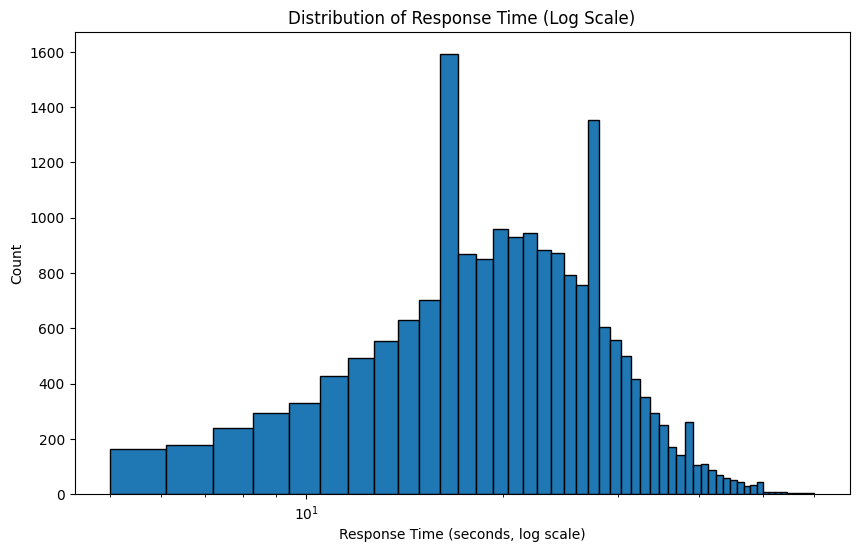

In [178]:
#figuring out which columns im supposed to use 
print(events_df['domain'].unique())

#making a dataframe of only the relevant data 

#get questionview timestamps
question_view_df = events_df[events_df['event_type'] == 'question_view'][['student_id', 'question_id', 'timestamp']].rename(columns={'timestamp': 'view_time'})

#get answer submit timestamps
answer_submit_df = events_df[events_df['event_type'] == 'answer_submit'][['student_id', 'question_id', 'timestamp']].rename(columns={'timestamp': 'submit_time'})

#merge on student_id and question_id
response_times_df = answer_submit_df.merge(question_view_df, on=['student_id', 'question_id'])

#calculate response time in seconds
response_times_df['response_time_seconds'] = (
    pd.to_datetime(response_times_df['submit_time']) - 
    pd.to_datetime(response_times_df['view_time'])
).dt.total_seconds()

#plotting with a histogram
plt.figure(figsize=(10, 6))
plt.hist(response_times_df['response_time_seconds'], bins=50, edgecolor='black')
plt.xscale('log')  # ← add this
plt.xlabel('Response Time (seconds, log scale)')
plt.ylabel('Count')
plt.title('Distribution of Response Time (Log Scale)')
plt.show()




Why did you choose this approach over a standard histogram on a linear scale?

The log scale histogram is better than doing a linear scale for this data because on a linear scale, the bulk of the data gets compressed into a narrow region on the left, making the shape of the distribution hard to read. A log scale compresses the tail and spreads out the dense region, making the overall distribution much more 
interpretable.

Part 3: SQL with DuckDB

For this entire part, register your DataFrames as DuckDB tables and use SQL for all computations. Do not use pandas for the analytical work itself (loading and registering is fine; plotting query results is fine).

In [166]:
#loading in the students csv as a df
students_df = pd.read_csv("C:/Users/ilian/Downloads/SI_345/DoU 5/si345_dou_5_data/data/students.csv") 

# registering the dataframes as duckdb tables 
duckdb.register('sessions', sessions_df)

duckdb.register('students', students_df)

duckdb.register('events', events_df)

duckdb.register('responses', responses_df)

duckdb.register('yaml', yaml_df)

#checking the columns to see if i used the right dfs 
print(sessions_df.columns.tolist())
print(students_df.columns.tolist())
print(events_df.columns.tolist())
print(responses_df.columns.tolist())
print(yaml_df.columns.tolist())

['session_id', 'student_id', 'domain', 'started_at', 'ended_at', 'abandoned', 'platform', 'n_questions_seen', 'browser', 'screen_width']
['student_id', 'uniqname', 'first_name', 'last_name', 'cohort', 'section', 'email', 'program']
['event_id', 'session_id', 'student_id', 'domain', 'event_type', 'question_id', 'value', 'timestamp']
['response_id', 'session_id', 'student_id', 'domain', 'question_id', 'selected_option', 'is_correct', 'response_time_seconds', 'sequence_position']
['domain', 'question_id', 'sub_skill', 'difficulty', 'dimension', 'correct_answer']


Task 3.1 -- Domain coverage

Write a SQL query that returns, for each domain, the number of distinct students who completed at least one non-abandoned session. Order by count descending.

In [177]:
#first i have to join the two dfs?  
r31 = duckdb.sql('''
SELECT r.domain, COUNT(DISTINCT s.student_id) AS student_count
FROM sessions s
JOIN responses r ON s.session_id = r.session_id
WHERE s.abandoned = false
GROUP BY r.domain
ORDER BY student_count DESC
''').df()

print(f"Number of distinct students that completed at least one non-abandoned session per domain: \n{r31}")


Number of distinct students that completed at least one non-abandoned session per domain: 
                domain  student_count
0          pandas_core            421
1  python_fundamentals            421
2           sql_duckdb            417
3             data_viz            403


The domain with the most students who completed at least one non-abandoned session was pandas_core and python_fundamentals (tied at 421), followed by sql_duckdb (417) and data_viz (403). The counts are pretty consistent across domains, suggesting most students engaged with all four areas. The slightly lower count in data_viz may indicate some students dropped or abandoned the course before reaching that domain, as the pandas core and pandas fundamentals are likely in the intro courses or in the beginning of courses compared to the other domains. 

Task 3.2 -- Accuracy by difficulty

Write a SQL query that joins responses to your question bank table and computes mean accuracy by difficulty level (D1, D2, D3). Exclude self-report questions (where is_correct is null). 

In [169]:
r32 = duckdb.sql('''
SELECT difficulty, AVG(CAST(is_correct AS INTEGER)) AS mean_accuracy
FROM responses r
JOIN yaml y ON r.question_id = y.question_id
WHERE r.is_correct IS NOT NULL
GROUP BY difficulty
ORDER BY difficulty ASC
''').df()

print(f"Pattern across difficulty levels: \n{r32}")


Pattern across difficulty levels: 
  difficulty  mean_accuracy
0         D1       0.699272
1         D2       0.690323
2         D3       0.677536


Does the pattern across difficulty levels make intuitive sense? Why or why not?

Yes, the pattern does make sense because the average accuracy goes down as the difficulty level goes up. This is expected because if the questions are harder, then people will have lower accuracy on average. 

Task 3.3 -- Accuracy by cohort and domain

Write a SQL query that produces mean accuracy per cohort per domain, for knowledge/application questions only. Your result should have columns: cohort, domain, mean_accuracy, n_responses. Order by cohort, then mean_accuracy descending.

In [162]:
r33 = duckdb.sql('''
SELECT 
    st.cohort,
    r.domain,
    AVG(CAST(is_correct AS INTEGER)) AS mean_accuracy,
    COUNT(*) AS n_responses
FROM responses r
JOIN students st ON r.student_id = st.student_id
WHERE is_correct IS NOT NULL
GROUP BY st.cohort, r.domain
ORDER BY st.cohort, mean_accuracy DESC

''').df()

print(f"Mean Accuracy per Cohort per Domain: \n{r33}")

Mean Accuracy per Cohort per Domain: 
   cohort               domain  mean_accuracy  n_responses
0   F2025          pandas_core       0.705506          781
1   F2025  python_fundamentals       0.698501         1801
2   F2025           sql_duckdb       0.690476          672
3   F2025             data_viz       0.674603          504
4   W2025             data_viz       0.745283          212
5   W2025  python_fundamentals       0.699468          752
6   W2025           sql_duckdb       0.672932          266
7   W2025          pandas_core       0.663462          312
8   W2026             data_viz       0.696471          850
9   W2026           sql_duckdb       0.690282         1101
10  W2026  python_fundamentals       0.686827         2877
11  W2026          pandas_core       0.679654         1386


Task 3.4 -- Students who completed all four domains

Write a SQL query that returns the student_id and uniqname of students who completed (non-abandoned) sessions in all four domains. Use HAVING to filter groups after aggregation. 

In [ ]:
#
r34 = duckdb.sql('''
SELECT st.student_id, st.uniqname
FROM students st 
JOIN (
    SELECT student_id
    FROM sessions
    WHERE abandoned = false 
    GROUP BY student_id
    HAVING COUNT(DISTINCT domain) = 4
) completed ON st.student_id = completed.student_id
ORDER BY st.uniqname 
''').df()
# where is the uniqname column coming from?
print(f"Students who completed all 4 domains: {len(r34)}")
r34.head()

Students who completed all 4 domains: 248


,student_id,uniqname
0,U27588425,andeem17
1,U41383670,andemi19
2,U23425832,bauebe26
3,U03424420,baueel89
4,U32181960,baueem4


How many such students are there, and why must HAVING be used here rather than WHERE?

There are 248 students who completed all four domains. HAVING must be used rather than WHERE because the WHERE can't run before the grouping happens, but the COUNT part is in the JOIN, so using HAVING allows the COUNT to run after the group by instead. 

Task 3.5 -- Per-student ranking within domain

Write a SQL query using a window function that ranks students by their accuracy within each domain (highest accuracy = rank 1). Include only students who answered at least 5 knowledge/application questions in that domain. Return domain, student_id, accuracy, and domain_rank. Show the top 3 per domain.

In [181]:

r35 = duckdb.sql('''
SELECT * FROM (
    SELECT 
        domain,
        r.student_id,
        AVG(CAST(is_correct AS INTEGER)) AS accuracy,
        COUNT(*) AS n_responses,
        ROW_NUMBER() OVER (PARTITION BY domain ORDER BY AVG(CAST(is_correct AS INTEGER)) DESC) AS rank
    FROM responses r
    JOIN students st ON r.student_id = st.student_id
    WHERE is_correct IS NOT NULL
    GROUP BY domain, r.student_id
    HAVING COUNT(*) >= 5
) ranked
WHERE rank <= 3             
ORDER BY domain, rank ASC
''').df()

print(f"Top 3 students per domain: \n{r35}")

Top 3 students per domain: 
                domain student_id  accuracy  n_responses  rank
0          pandas_core  U15747338       1.0            6     1
1          pandas_core  U33898881       1.0            6     2
2          pandas_core  U78485880       1.0            6     3
3  python_fundamentals  U78427010       1.0           13     1
4  python_fundamentals  U58428241       1.0           13     2
5  python_fundamentals  U97265273       1.0           13     3
6           sql_duckdb  U69816934       1.0            5     1
7           sql_duckdb  U90835723       1.0            5     2
8           sql_duckdb  U53795020       1.0            5     3


There were a bunch of ties with students who had 100% accuracy, so I used ROW_NUMBER instead of RANK to only show 3. One of the domains had no students with more than 5 responses, so it wasn't included.

Task 3.6 -- Response time trend across sequence position

Write a SQL query that computes mean response_time_seconds by sequence_position, for knowledge/application questions only. Plot the result using matplotlib. 

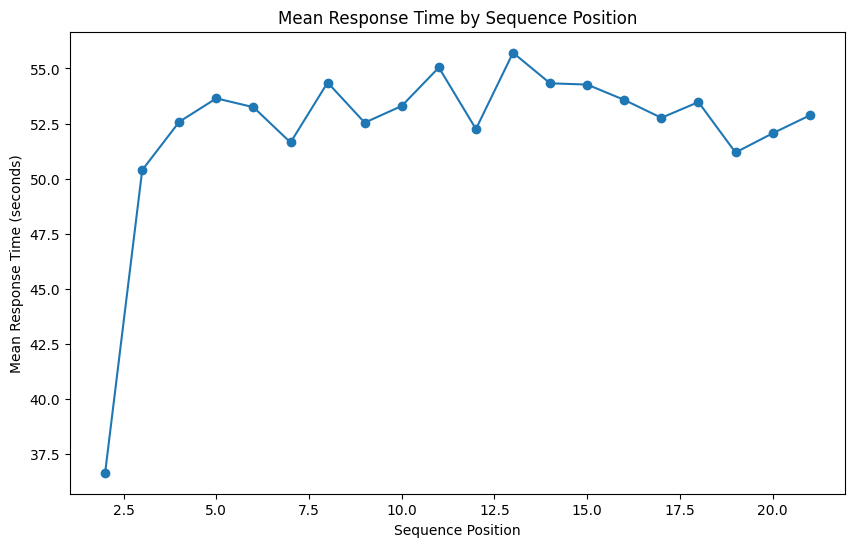

In [176]:
r36 = duckdb.sql('''
SELECT 
    sequence_position,
    AVG(response_time_seconds) AS mean_response_time
FROM responses
WHERE is_correct IS NOT NULL
GROUP BY sequence_position
ORDER BY sequence_position ASC
''').df()

plt.figure(figsize=(10, 6))
plt.plot(r36['sequence_position'], r36['mean_response_time'], marker='o')
plt.xlabel('Sequence Position')
plt.ylabel('Mean Response Time (seconds)')
plt.title('Mean Response Time by Sequence Position')
plt.show()

Do response times change as students progress through a session, and what might explain the pattern you see?

Response times increase sharply from the first question (~37 seconds) to around position 3-5 (~53 seconds), then plateau and stay relatively stable for the rest of the session. This makes sense because the first question in a session likely captures the time students spend reading instructions and getting set up, which inflates the response time for early questions. After getting settled, students have a consistent working pace with no clear signs of slowing down or speeding up as they progress through the session.

Part 4: Synthesis 

Task 4.1 -- One finding of your choice

Using either pandas or SQL (your choice), identify one additional finding about student behavior or performance that you find interesting. It should go beyond restating a task result -- find something that surprised you or that you think would be actionable for an instructor.

In [179]:
r41 = duckdb.sql('''
SELECT 
    st.program,
    COUNT(DISTINCT st.student_id) AS n_students,
    AVG(CAST(r.is_correct AS INTEGER)) AS mean_accuracy,
    COUNT(*) AS n_responses
FROM responses r
JOIN students st ON r.student_id = st.student_id
WHERE r.is_correct IS NOT NULL
GROUP BY st.program
ORDER BY mean_accuracy DESC
''').df()

print(r41)

  program  n_students  mean_accuracy  n_responses
0    None           7       0.703226          155
1     PhD         151       0.699199         3371
2     BSI         123       0.694567         2724
3     MHI         117       0.686865         2657
4     MSI         118       0.678941         2607


What did you find, and why does it matter? 

I looked at the average accuracy of students across different programs. I found that students who are listed in none of the programs have the highest mean accuracy of questions, but this group had the smallest number of students, so it was likely outliers. Among the programs that are named, the PhD program had the highest mean accuracy (69.92%) and the most responses and most individual students. PhD programs likely have the most exposure to the variety of questions from different libraries listed in the dataframe, and the longest amount of experience coding. This could lead to them having the highest accuracy-- but it is also important to note that all of the accuracies are within 3% of each other. One thing that was interesting to me was that the BSI students had the third highest accuracy, despite being undergraduate students. The information I looked at didn't account for difficulty of the questions, so this could be related to undergraduate programs having a lower level of difficulty than graduate programs. 